# Eksperimen & Modeling K-Nearest Neighbors (KNN)
**PIC:** Irfan (Anggota 4 — Deployment Engineer)  
**Dataset:** `dataset_final_tbp/output/` (80.000 train, 20.000 test, 9 fitur)  
**Target:** `Status Kelulusan` (`0` = Dropout, `1` = Graduate)

Tahapan dalam notebook ini:
1. Memuat dataset bersama (`X_train`, `X_test`, `y_train`, `y_test`) dan `scaler.pkl`.
2. Eksperimen pencarian nilai `k` terbaik (`k = 3, 5, 7, 9, 11, 15, 21`).
3. Evaluasi model terbaik pada data uji (*Accuracy, Precision, Recall Dropout, F1-Score, ROC-AUC, Confusion Matrix*).
4. Menyimpan model terbaik ke `models/knn_model.pkl` dan ringkasan metrik ke `evaluation/knn_metrics.json`.

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore", category=UserWarning)

DATA_DIR = Path("../dataset_final_tbp/output")
MODEL_DIR = Path("../models")
EVAL_DIR = Path("../evaluation")
MODEL_DIR.mkdir(exist_ok=True)
EVAL_DIR.mkdir(exist_ok=True)

## 1. Memuat Dataset & Standardisasi Fitur
Algoritma KNN menghitung jarak Euclidean antar titik data, sehingga seluruh fitur wajib berada pada skala yang sama menggunakan `scaler.pkl` (yang hanya di-fit pada `X_train`).

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

scaler = joblib.load(DATA_DIR / "scaler.pkl")
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train_scaled.shape} | X_test: {X_test_scaled.shape}")
print("Proporsi kelas y_test:", y_test.value_counts().to_dict())

X_train: (80000, 9) | X_test: (20000, 9)
Proporsi kelas y_test: {0: 10008, 1: 9992}


## 2. Eksperimen Pencarian Nilai `k` Terbaik
Menguji beberapa nilai `k` ganjil (`3, 5, 7, 9, 11, 15, 21`) untuk melihat pengaruh jumlah tetangga terhadap performa dan waktu komputasi.

In [3]:
k_values = [3, 5, 7, 9, 11, 15, 21]
results = []

for k in k_values:
    t0 = time.perf_counter()
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    train_time = time.perf_counter() - t0

    t1 = time.perf_counter()
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    pred_time = time.perf_counter() - t1

    results.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_Dropout": precision_score(y_test, y_pred, pos_label=0),
        "Recall_Dropout": recall_score(y_test, y_pred, pos_label=0),
        "F1_Score": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "Train_Time_s": round(train_time, 4),
        "Pred_Time_s": round(pred_time, 4),
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,k,Accuracy,Precision_Dropout,Recall_Dropout,F1_Score,ROC_AUC,Train_Time_s,Pred_Time_s
0,3,0.5017,0.5021,0.4936,0.5055,0.5008,0.2894,1.2180
1,5,0.5016,0.5021,0.4971,0.5037,0.5023,0.3387,1.5009
2,7,0.5039,0.5043,0.4990,0.5061,0.5024,0.3159,1.7602
3,9,0.4986,0.4990,0.4934,0.5011,0.5004,0.2870,2.3439
4,11,0.5018,0.5023,0.5004,0.5024,0.4987,0.2587,2.1017
5,15,0.5026,0.5031,0.5011,0.5032,0.5013,0.2501,2.4257
6,21,0.4984,0.4988,0.4956,0.4997,0.4994,0.2696,2.8915


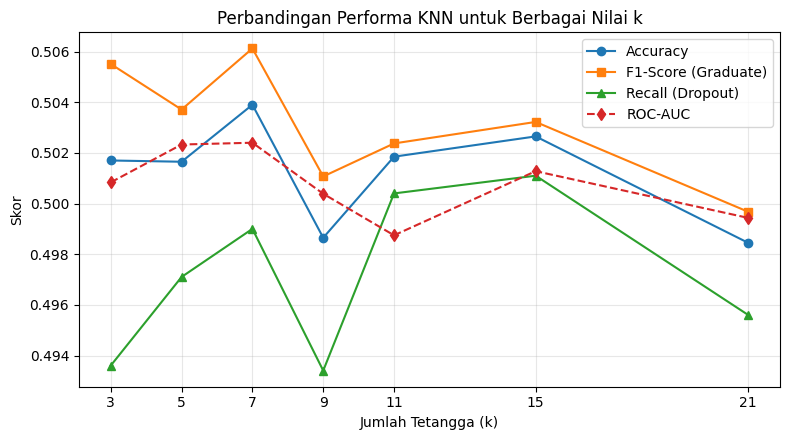

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(results_df["k"], results_df["Accuracy"], marker="o", label="Accuracy")
ax.plot(results_df["k"], results_df["F1_Score"], marker="s", label="F1-Score (Graduate)")
ax.plot(results_df["k"], results_df["Recall_Dropout"], marker="^", label="Recall (Dropout)")
ax.plot(results_df["k"], results_df["ROC_AUC"], marker="d", linestyle="--", label="ROC-AUC")
ax.set_title("Perbandingan Performa KNN untuk Berbagai Nilai k")
ax.set_xlabel("Jumlah Tetangga (k)")
ax.set_ylabel("Skor")
ax.set_xticks(k_values)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Pelatihan & Evaluasi Model Terbaik
Memilih nilai `k` dengan kombinasi `ROC_AUC` dan `F1_Score` tertinggi, lalu menampilkan `classification_report`, *Confusion Matrix*, dan kurva *ROC-AUC*.

In [5]:
best_row = results_df.sort_values(by=["ROC_AUC", "F1_Score"], ascending=False).iloc[0]
best_k = int(best_row["k"])
print(f"Nilai k terbaik terpilih: k = {best_k}")

t0 = time.perf_counter()
best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train_scaled, y_train)
best_train_time = time.perf_counter() - t0

y_pred_best = best_knn.predict(X_test_scaled)
y_proba_best = best_knn.predict_proba(X_test_scaled)[:, 1]

print("\nClassification Report (0 = Dropout, 1 = Graduate):")
print(classification_report(y_test, y_pred_best, target_names=["Dropout (0)", "Graduate (1)"], digits=4))

Nilai k terbaik terpilih: k = 7



Classification Report (0 = Dropout, 1 = Graduate):
              precision    recall  f1-score   support

 Dropout (0)     0.5043    0.4990    0.5017     10008
Graduate (1)     0.5035    0.5088    0.5061      9992

    accuracy                         0.5039     20000
   macro avg     0.5039    0.5039    0.5039     20000
weighted avg     0.5039    0.5039    0.5039     20000



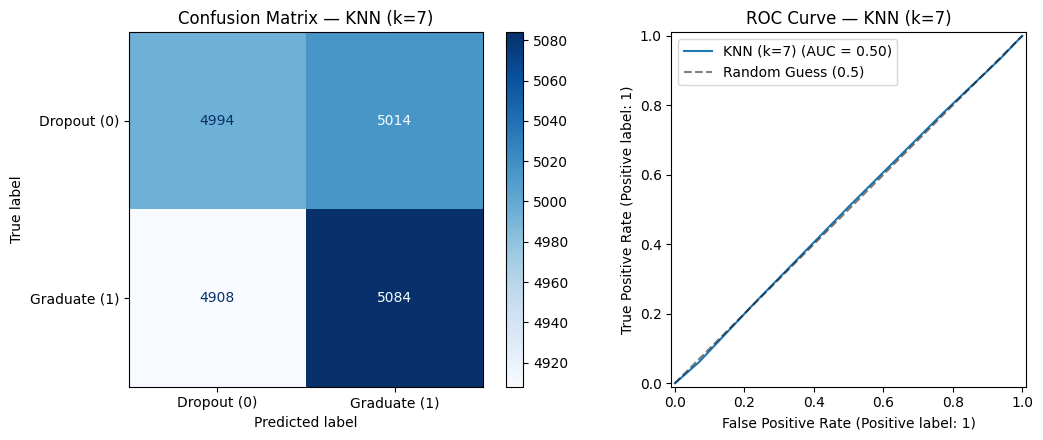

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Dropout (0)", "Graduate (1)"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix — KNN (k={best_k})")

RocCurveDisplay.from_predictions(
    y_test,
    y_proba_best,
    name=f"KNN (k={best_k})",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (0.5)")
axes[1].set_title(f"ROC Curve — KNN (k={best_k})")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Simpan Model & Metrik Evaluasi
Menyimpan model terbaik ke `models/knn_model.pkl` dan metrik ringkasan ke `evaluation/knn_metrics.json` untuk komparasi tim.

In [7]:
model_path = MODEL_DIR / "knn_model.pkl"
joblib.dump(best_knn, model_path)

metrics_summary = {
    "model": f"K-Nearest Neighbors (k={best_k})",
    "pic": "Irfan",
    "best_params": {"n_neighbors": best_k, "metric": "minkowski", "p": 2},
    "accuracy": round(float(accuracy_score(y_test, y_pred_best)), 4),
    "precision_dropout": round(float(precision_score(y_test, y_pred_best, pos_label=0)), 4),
    "recall_dropout": round(float(recall_score(y_test, y_pred_best, pos_label=0)), 4),
    "f1_score_dropout": round(float(f1_score(y_test, y_pred_best, pos_label=0)), 4),
    "precision_graduate": round(float(precision_score(y_test, y_pred_best, pos_label=1)), 4),
    "recall_graduate": round(float(recall_score(y_test, y_pred_best, pos_label=1)), 4),
    "f1_score_graduate": round(float(f1_score(y_test, y_pred_best, pos_label=1)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, y_proba_best)), 4),
    "train_time_s": round(float(best_train_time), 4),
}

metrics_path = EVAL_DIR / "knn_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2)

print("Model tersimpan di:", model_path.resolve())
print("Metrik tersimpan di:", metrics_path.resolve())
print(json.dumps(metrics_summary, indent=2))

Model tersimpan di: C:\Users\irfan\Kuliah\INFORMATIKA UNS\Semester 5\datmin\Team-Based Project\Kelompok-4_Team-Based-Project_Data-Mining\models\knn_model.pkl
Metrik tersimpan di: C:\Users\irfan\Kuliah\INFORMATIKA UNS\Semester 5\datmin\Team-Based Project\Kelompok-4_Team-Based-Project_Data-Mining\evaluation\knn_metrics.json
{
  "model": "K-Nearest Neighbors (k=7)",
  "pic": "Irfan",
  "best_params": {
    "n_neighbors": 7,
    "metric": "minkowski",
    "p": 2
  },
  "accuracy": 0.5039,
  "precision_dropout": 0.5043,
  "recall_dropout": 0.499,
  "f1_score_dropout": 0.5017,
  "precision_graduate": 0.5035,
  "recall_graduate": 0.5088,
  "f1_score_graduate": 0.5061,
  "roc_auc": 0.5024,
  "train_time_s": 0.2478
}
